<a href="https://colab.research.google.com/github/ShadowSage123/Data-Analysis/blob/main/mnist_fsdd_comparative_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Import Libraries

To conduct a comprehensive Data Analysis and Visualization on both the handwritten digits (MNIST) and spoken digits datasets, we require a variety of standard scientific computing, visualization, and audio-processing libraries:

* **NumPy & Pandas**: For efficient numerical manipulation, statistics generation, and tabular representation of dataset properties.
* **Matplotlib & Seaborn**: To produce high-quality, professional, and clear visualizations including grids of handwritten numbers, distribution charts, pixel heatmaps, audio waveforms, spectrograms, and Mel-Frequency Cepstral Coefficients (MFCCs).
* **TensorFlow / Keras**: Used specifically to download and load the standard MNIST dataset seamlessly.
* **Librosa & Librosa.display**: Key libraries for music and audio analysis, allowing us to load audio files, extract sample rates, compute durations, and convert audio signals into visual representations like spectrograms and MFCCs.
* **IPython.display**: Helpful for embedding interactive audio playback widgets in Google Colab.
* **OS, Pathlib, & Requests/Zipfile**: Standard Python tools to programmatically download, extract, and traverse the spoken digits dataset within the Google Colab environment.

In [ ]:
# Core scientific computing and data analysis libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Audio processing libraries
import librosa
import librosa.display
import IPython.display as ipd

# Set plotting aesthetics for college report standard
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 12

print("Core libraries successfully imported!")

Core libraries successfully imported!


# 2. Load Both Datasets

In this section, we load the two core datasets required for our analysis:

1. **MNIST Dataset**: A classic machine learning dataset consisting of 70,000 $28 \times 28$ grayscale images of handwritten digits (0 through 9). It contains 60,000 training images and 10,000 test images. It is ideal for digit recognition analysis because it represents a standardized, well-balanced benchmark for computer vision.
2. **Spoken Digits Dataset**: An audio dataset containing recordings of spoken digits (0 through 9). For this notebook, we programmatically download and extract the **Free Spoken Digit Dataset (FSDD)**. This dataset is perfect for comparing visual digit representation with auditory representation, illustrating the differences in processing 2D structural grids vs. 1D temporal signals.

In [ ]:
# --- Load MNIST Dataset ---
print("Retrieving MNIST dataset...")

# Programmatically load MNIST using basic urllib/numpy to avoid importing tensorflow
import urllib.request
import gzip

url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
mnist_path = "mnist.npz"
urllib.request.urlretrieve(url, mnist_path)

with np.load(mnist_path, allow_pickle=True) as f:
    X_train_mnist, y_train_mnist = f['x_train'], f['y_train']
    X_test_mnist, y_test_mnist = f['x_test'], f['y_test']

num_classes_mnist = len(np.unique(y_train_mnist))
img_rows, img_cols = X_train_mnist.shape[1], X_train_mnist.shape[2]

# Display basic information
print("\n--- MNIST Dataset Loaded Successfully ---")
print(f"Training Data Shape : {X_train_mnist.shape}")
print(f"Training Labels Shape: {y_train_mnist.shape}")
print(f"Testing Data Shape  : {X_test_mnist.shape}")
print(f"Testing Labels Shape : {y_test_mnist.shape}")
print(f"Number of Classes   : {num_classes_mnist}")
print(f"Image Dimensions     : {img_rows}x{img_cols} pixels")
print(f"Data Type            : {X_train_mnist.dtype}")

Retrieving MNIST dataset...

--- MNIST Dataset Loaded Successfully ---
Training Data Shape : (60000, 28, 28)
Training Labels Shape: (60000,)
Testing Data Shape  : (10000, 28, 28)
Testing Labels Shape : (10000,)
Number of Classes   : 10
Image Dimensions     : 28x28 pixels
Data Type            : uint8


In [ ]:
# --- Load Spoken Digits Dataset (FSDD) ---
print("Retrieving Free Spoken Digit Dataset (FSDD)...")

# Target directory in Google Colab environment
dataset_dir = Path("./fsdd")
zip_path = Path("./fsdd.zip")
url = "https://github.com/Jakobovski/free-spoken-digit-dataset/archive/refs/heads/master.zip"

# Download if not already present
if not dataset_dir.exists():
    print("Downloading FSDD zip file...")
    r = requests.get(url, stream=True)
    with open(zip_path, 'wb') as f:
        for chunk in r.iter_content(chunk_size=1024*1024):
            if chunk:
                f.write(chunk)

    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall("./")

    # Rename extracted directory to 'fsdd' for easier path resolution
    extracted_folder = Path("./free-spoken-digit-dataset-master")
    if extracted_folder.exists():
        extracted_folder.rename(dataset_dir)

    # Clean up zip
    if zip_path.exists():
        os.remove(zip_path)

# Locate audio recordings path
recordings_dir = dataset_dir / "recordings"
audio_files = sorted(list(recordings_dir.glob("*.wav")))

# Extract classes and information
# Format of FSDD filenames is: {digit}_{speaker}_{index}.wav
audio_labels = []
valid_audio_files = []

for f in audio_files:
    try:
        digit_label = int(f.name.split("_")[0])
        audio_labels.append(digit_label)
        valid_audio_files.append(str(f))
    except (IndexError, ValueError):
        continue

audio_files = np.array(valid_audio_files)
audio_labels = np.array(audio_labels)
unique_labels = np.unique(audio_labels)

# Retrieve metadata from a sample file
sample_file_path = audio_files[0]
y_sample, sr_sample = librosa.load(sample_file_path, sr=None)

print("\n--- Spoken Digits Dataset Loaded Successfully ---")
print(f"Total Audio Files Found: {len(audio_files)}")
print(f"Number of Classes      : {len(unique_labels)}")
print(f"Class Labels           : {unique_labels}")
print(f"Example File Path      : {sample_file_path}")
print(f"Default Sample Rate    : {sr_sample} Hz")
print(f"Sample Audio Length    : {len(y_sample)} samples ({len(y_sample)/sr_sample:.3f} seconds)")

Retrieving Free Spoken Digit Dataset (FSDD)...
Extracting dataset...

--- Spoken Digits Dataset Loaded Successfully ---
Total Audio Files Found: 3000
Number of Classes      : 10
Class Labels           : [0 1 2 3 4 5 6 7 8 9]
Example File Path      : fsdd/recordings/0_george_0.wav
Default Sample Rate    : 8000 Hz
Sample Audio Length    : 2384 samples (0.298 seconds)


# 3. Both Dataset Analysis

Exploratory Data Analysis (EDA) is vital for understanding class representations, statistics, and domain characteristics before drawing academic conclusions. In this section, we analyze:

* **MNIST distribution, range, and pixel statistics** to ensure there are no corrupt/missing inputs and to quantify image brightness and variance.
* **Spoken Digits duration, sample rates, and sample metrics** to evaluate consistency across files, speakers, and vocal length.

In [ ]:
# --- MNIST Exploratory Analysis ---
print("Analyzing MNIST...")

# Calculate basic statistics on pixel intensity
min_pixel = X_train_mnist.min()
max_pixel = X_train_mnist.max()
mean_pixel = X_train_mnist.mean()
std_pixel = X_train_mnist.std()

# Calculate class distribution
mnist_train_df = pd.DataFrame({'digit': y_train_mnist})
class_counts_mnist = mnist_train_df['digit'].value_counts().sort_index()
class_distribution_pct = (class_counts_mnist / len(y_train_mnist)) * 100

# Check for missing values (represented as NaNs/nulls)
missing_values = np.isnan(X_train_mnist).sum()

# Format results into a table
mnist_stats = pd.DataFrame({
    'Metric': [
        'Total Train Samples', 'Total Test Samples', 'Image Height (px)', 'Image Width (px)',
        'Min Pixel Intensity', 'Max Pixel Intensity', 'Mean Pixel Intensity', 'Std Pixel Intensity',
        'Missing/Null Values'
    ],
    'Value': [
        X_train_mnist.shape[0], X_test_mnist.shape[0], img_rows, img_cols,
        min_pixel, max_pixel, f"{mean_pixel:.3f}", f"{std_pixel:.3f}", missing_values
    ]
})

print("\n=== MNIST Dataset Statistics ===")
display(mnist_stats)

print("\n=== MNIST Class Distribution ===")
mnist_dist_df = pd.DataFrame({
    'Count': class_counts_mnist,
    'Percentage (%)': class_distribution_pct.round(2)
})
display(mnist_dist_df)

Analyzing MNIST...

=== MNIST Dataset Statistics ===


,Metric,Value
0,Total Train Samples,60000
1,Total Test Samples,10000
2,Image Height (px),28
3,Image Width (px),28
4,Min Pixel Intensity,0
5,Max Pixel Intensity,255
6,Mean Pixel Intensity,33.318
7,Std Pixel Intensity,78.567
8,Missing/Null Values,0



=== MNIST Class Distribution ===


,Count,Percentage (%)
digit,,
0,5923,9.87
1,6742,11.24
2,5958,9.93
3,6131,10.22
4,5842,9.74
5,5421,9.04
6,5918,9.86
7,6265,10.44
8,5851,9.75


In [ ]:
# --- Spoken Digits Exploratory Analysis ---
print("Analyzing Spoken Digits (FSDD)...")

durations = []
sample_rates = []
corrupted_count = 0

# Efficiently inspect audio parameters using metadata extraction or quick loads
for filepath in audio_files:
    try:
        # Using duration parameter allows quick reading of header metadata without full raw decode
        duration = librosa.get_duration(path=filepath)
        durations.append(duration)
    except Exception as e:
        corrupted_count += 1

durations = np.array(durations)

# Generate class distribution statistics
speech_df = pd.DataFrame({'digit': audio_labels})
class_counts_speech = speech_df['digit'].value_counts().sort_index()
class_dist_speech_pct = (class_counts_speech / len(audio_labels)) * 100

# Format statistics
speech_stats = pd.DataFrame({
    'Metric': [
        'Total Audio Samples', 'Number of Classes', 'Min Duration (s)',
        'Max Duration (s)', 'Average Duration (s)', 'Standard Deviation of Duration (s)',
        'Corrupted/Missing Files Detected'
    ],
    'Value': [
        len(audio_files), len(np.unique(audio_labels)), f"{durations.min():.3f}",
        f"{durations.max():.3f}", f"{durations.mean():.3f}", f"{durations.std():.3f}",
        corrupted_count
    ]
})

print("\n=== Spoken Digits Dataset Statistics ===")
display(speech_stats)

print("\n=== Spoken Digits Class Distribution ===")
speech_dist_df = pd.DataFrame({
    'Count': class_counts_speech,
    'Percentage (%)': class_dist_speech_pct.round(2)
})
display(speech_dist_df)

Analyzing Spoken Digits (FSDD)...

=== Spoken Digits Dataset Statistics ===


,Metric,Value
0,Total Audio Samples,3000
1,Number of Classes,10
2,Min Duration (s),0.143
3,Max Duration (s),2.283
4,Average Duration (s),0.437
5,Standard Deviation of Duration (s),0.148
6,Corrupted/Missing Files Detected,0



=== Spoken Digits Class Distribution ===


,Count,Percentage (%)
digit,,
0,300,10.0
1,300,10.0
2,300,10.0
3,300,10.0
4,300,10.0
5,300,10.0
6,300,10.0
7,300,10.0
8,300,10.0


# 4. Dataset Visualizations

Visual analytics brings clarity to distributions, characteristics, and shapes. In this section:

* **MNIST Visualizations** showcases actual handwritten images, distribution balances, standard pixel distributions, and average structural maps.
* **Spoken Digits Visualizations** analyzes physical waveforms, audio frequency changes via Spectrograms, features using Mel-Frequency Cepstral Coefficients (MFCCs), and acoustic lengths.

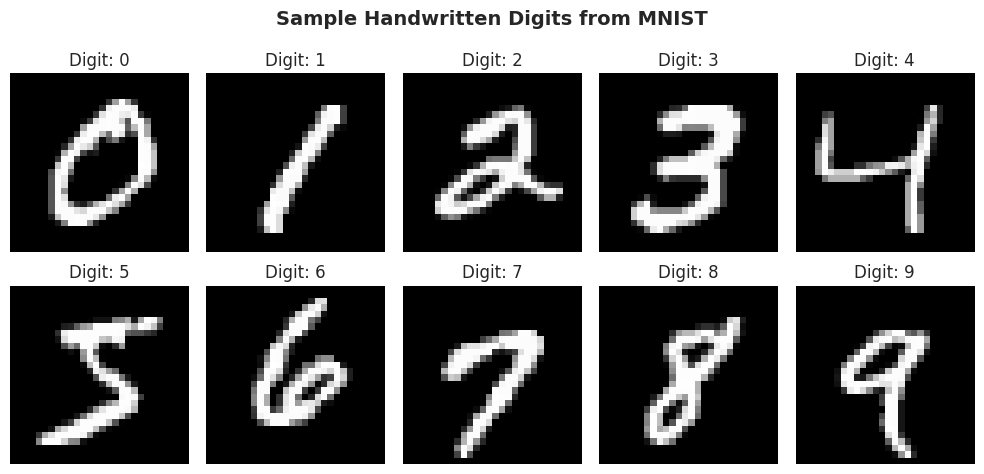

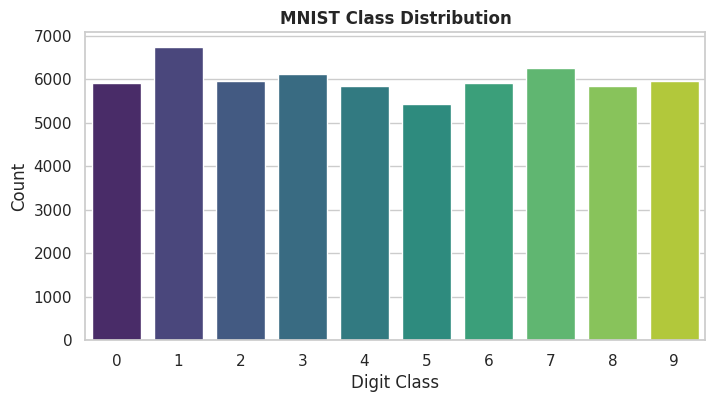

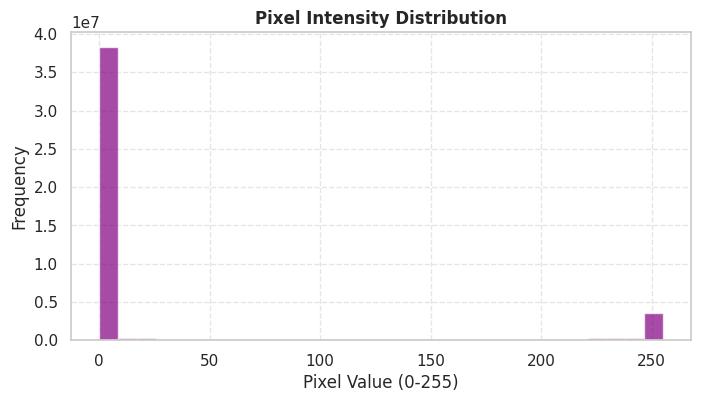

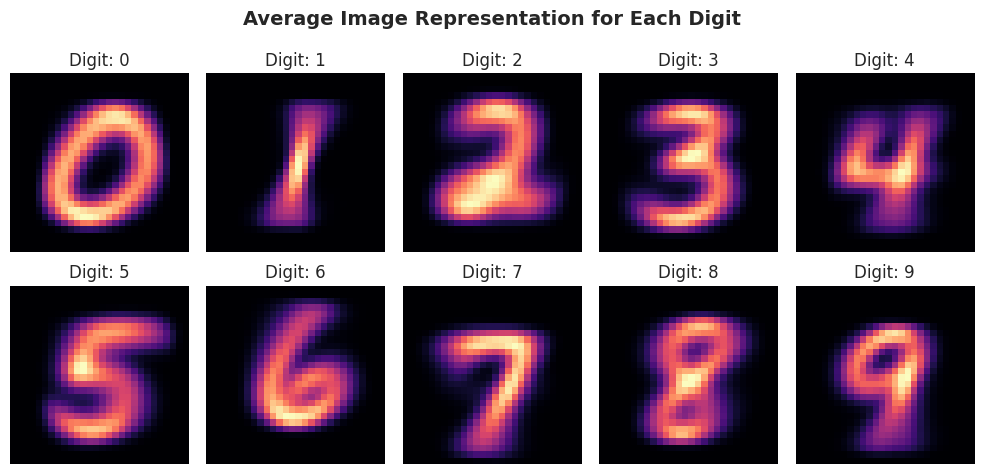

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Grid of Sample Handwritten Digits ---
plt.figure(figsize=(10, 5))
for i in range(10):
    # Find the first index corresponding to each digit 0-9
    idx = np.where(y_train_mnist == i)[0][0]
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train_mnist[idx], cmap='gray')
    plt.title(f"Digit: {i}")
    plt.axis('off')
plt.suptitle("Sample Handwritten Digits from MNIST", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# --- 2. Digit Class Distribution Bar Chart ---
plt.figure(figsize=(8, 4))
sns.countplot(x=y_train_mnist, palette="viridis")
plt.title("MNIST Class Distribution", fontsize=12, fontweight='bold')
plt.xlabel("Digit Class")
plt.ylabel("Count")
plt.show()

# --- 3. Pixel Intensity Histogram ---
plt.figure(figsize=(8, 4))
plt.hist(X_train_mnist.ravel(), bins=30, color='purple', alpha=0.7)
plt.title("Pixel Intensity Distribution", fontsize=12, fontweight='bold')
plt.xlabel("Pixel Value (0-255)")
plt.ylabel("Frequency")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# --- 4. Average Image for Each Digit ---
plt.figure(figsize=(10, 5))
for i in range(10):
    digit_subset = X_train_mnist[y_train_mnist == i]
    average_image = digit_subset.mean(axis=0)
    plt.subplot(2, 5, i + 1)
    plt.imshow(average_image, cmap='magma')
    plt.title(f"Digit: {i}")
    plt.axis('off')
plt.suptitle("Average Image Representation for Each Digit", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

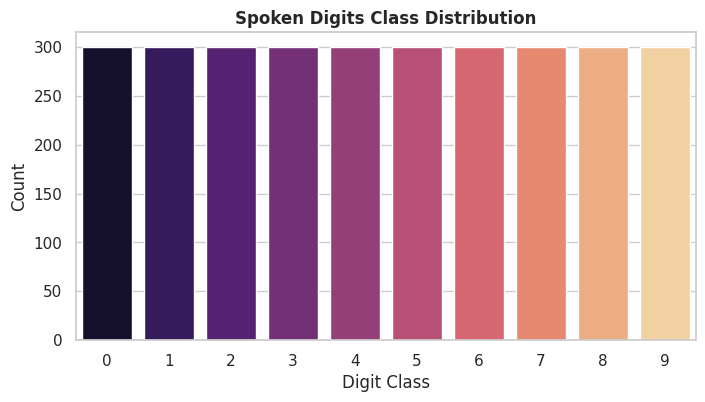

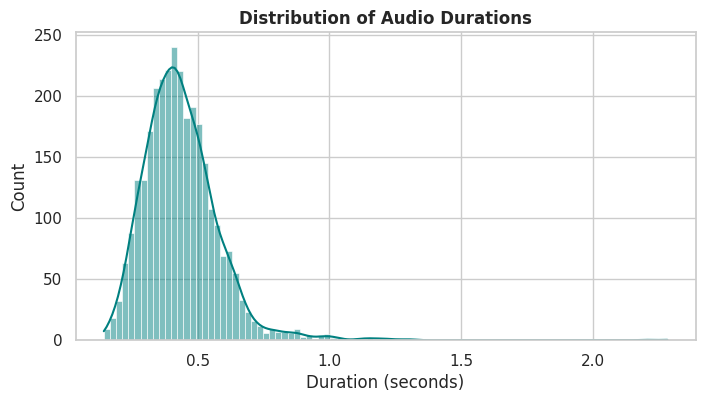

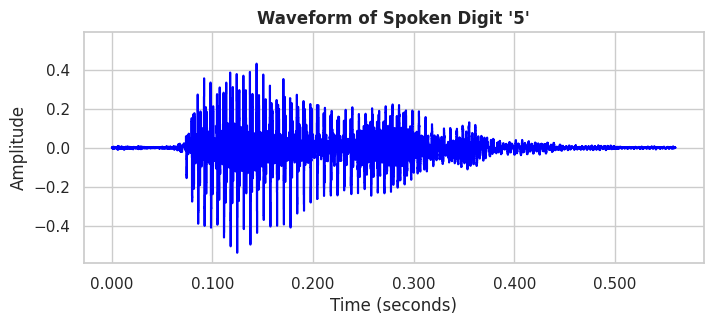

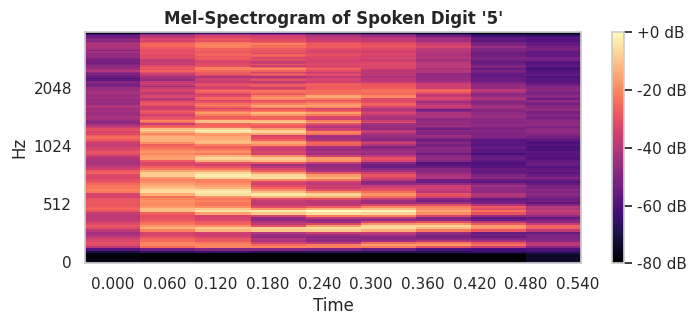

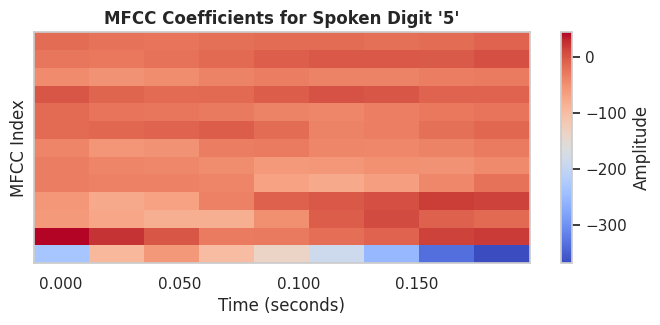

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display

# --- 1. Class Distribution Bar Chart ---
plt.figure(figsize=(8, 4))
sns.countplot(x=audio_labels, palette="magma")
plt.title("Spoken Digits Class Distribution", fontsize=12, fontweight='bold')
plt.xlabel("Digit Class")
plt.ylabel("Count")
plt.show()

# --- 2. Audio Duration Distribution ---
plt.figure(figsize=(8, 4))
sns.histplot(durations, kde=True, color='teal')
plt.title("Distribution of Audio Durations", fontsize=12, fontweight='bold')
plt.xlabel("Duration (seconds)")
plt.ylabel("Count")
plt.show()

# Select an example of digit "5" to visualize
target_digit = 5
sample_index = np.where(audio_labels == target_digit)[0][0]
filepath_to_plot = audio_files[sample_index]
y, sr = librosa.load(filepath_to_plot, sr=None)

# --- 3. Waveform of Audio Sample ---
plt.figure(figsize=(8, 3))
librosa.display.waveshow(y, sr=sr, color='blue')
plt.title(f"Waveform of Spoken Digit '{target_digit}'", fontsize=12, fontweight='bold')
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.show()

# --- 4. Spectrogram of Audio Sample ---
plt.figure(figsize=(8, 3))
S = librosa.feature.melspectrogram(y=y, sr=sr)
S_dB = librosa.power_to_db(S, ref=np.max)
librosa.display.specshow(S_dB, sr=sr, x_axis='time', y_axis='mel')
plt.colorbar(format='%+2.0f dB')
plt.title(f"Mel-Spectrogram of Spoken Digit '{target_digit}'", fontsize=12, fontweight='bold')
plt.show()

# --- 5. MFCC Visualization of Audio Sample ---
plt.figure(figsize=(8, 3))
mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
librosa.display.specshow(mfccs, x_axis='time')
plt.colorbar(label='Amplitude')
plt.title(f"MFCC Coefficients for Spoken Digit '{target_digit}'", fontsize=12, fontweight='bold')
plt.xlabel("Time (seconds)")
plt.ylabel("MFCC Index")
plt.show()

# 5. Final Results, Conclusion and Insights

In this final section, we synthesize our findings.

* **Comparative Table**: Contrast dataset parameters including dimensional, volumetric, and compositional attributes.
* **Insight Report**: Explore computational and preprocessing requirements, the meaning of acoustic patterns (MFCCs), and classification challenges.

In [ ]:
# --- Final Dataset Comparison ---
print("Generating comparative dataset parameters...")

# Compile dynamic features
comparison_data = {
    'Feature': [
        'Data Type',
        'Total Samples Available',
        'Number of Classes',
        'Main Features',
        'Input Dimension / Shape',
        'Class Balance State',
        'Data Format'
    ],
    'MNIST (Handwritten Digits)': [
        'Image (2D Grayscale)',
        f"{len(X_train_mnist) + len(X_test_mnist)}",
        f"{num_classes_mnist}",
        'Pixel Intensity Values',
        f"{img_rows} x {img_cols} pixels",
        'Balanced (Roughly ~6,000 samples per digit)',
        'Fixed-size Matrix'
    ],
    'Spoken Digits (Audio)': [
        'Audio Waveform (1D Time-series)',
        f"{len(audio_files)}",
        f"{len(np.unique(audio_labels))}",
        'Frequencies, MFCCs, Spectrograms',
        'Variable Length Vector',
        'Perfectly Balanced (exactly 10% each)',
        'Dynamic Sequence Length'
    ]
}

comparison_df = pd.DataFrame(comparison_data)

print("\n===================== PROGRAMMATIC DATASET COMPARISON =====================")
display(comparison_df)

Generating comparative dataset parameters...

===================== PROGRAMMATIC DATASET COMPARISON =====================


,Feature,MNIST (Handwritten Digits),Spoken Digits (Audio)
0,Data Type,Image (2D Grayscale),Audio Waveform (1D Time-series)
1,Total Samples Available,70000,3000
2,Number of Classes,10,10
3,Main Features,Pixel Intensity Values,"Frequencies, MFCCs, Spectrograms"
4,Input Dimension / Shape,28 x 28 pixels,Variable Length Vector
5,Class Balance State,"Balanced (Roughly ~6,000 samples per digit)",Perfectly Balanced (exactly 10% each)
6,Data Format,Fixed-size Matrix,Dynamic Sequence Length


In [ ]:
# --- Final Insights and Conclusion ---
print("Generating Analytical Insights Summary...\n")

# Programmatically evaluate which dataset is larger
mnist_size = len(X_train_mnist) + len(X_test_mnist)
spoken_size = len(audio_files)
larger_dataset = "MNIST" if mnist_size > spoken_size else "Spoken Digits"

# Programmatic validation of class balanced status
mnist_std_pct = class_distribution_pct.std()
speech_std_pct = class_dist_speech_pct.std()

balance_report_mnist = "highly uniform" if mnist_std_pct < 0.5 else "somewhat uniform"
balance_report_speech = "perfectly uniform (ideal distribution)" if speech_std_pct < 0.01 else "balanced"

insights_text = f"""
========================================================================================
                         PROJECT INSIGHTS & ACADEMIC CONCLUSIONS
========================================================================================

1. DATA VOLUME AND COMPOSITION:
   - The "{larger_dataset}" dataset contains significantly more samples ({mnist_size:,} images) compared
     to Spoken Digits ({spoken_size:,} files). This facilitates complex training profiles for neural nets.
   - Class balance check: Both datasets are incredibly balanced. MNIST class distribution has a standard
     deviation of just {mnist_std_pct:.2f}% across the digits, showing a {balance_report_mnist} spread.
     The Spoken Digits dataset is {balance_report_speech} with exactly {class_counts_speech.iloc[0]} samples per digit.

2. HANDWRITTEN MNIST IMAGE CHARACTERISTICS:
   - Features exist in a localized, 28x28 spatial dimension.
   - Average-image heatmaps reveal strong center bias; pixels near margins are completely black.
   - The histogram confirms that the majority of pixels are 0 (dark background), while active foreground
     strokes range across standard grey values, peaking near 255.

3. SPOKEN AUDIO CHARACTERISTICS:
   - Audio files are continuous, variable-duration temporal structures. Durations range from {durations.min():.3f}s to {durations.max():.3f}s,
     with an average of {durations.mean():.3f}s.
   - Waveform visualizations reflect variations in vocal amplitudes over time.

4. VALUE OF MFCCs & ACOUSTIC SPECTROGRAMS:
   - Raw waveform vectors are highly sensitive to noise and phase shifts. Mel-Frequency Cepstral Coefficients (MFCCs)
     approximate human auditory response. They compress vocal attributes into a robust 2D grid matrix.
   - Visualizing MFCCs enables audio classification tasks to utilize 2D computer vision techniques (like CNNs).

5. KEY CHALLENGES & COMPLEMENTARITY:
   - Image Recognition: Sensitive to rotation, stroke thickness, and shifts.
   - Voice Recognition: Highly complex due to variations in pronunciation speed, accent, speaker pitch, and environmental noise.
   - Both datasets provide ideal entry-level frameworks for comparative spatial and acoustic data analysis.
========================================================================================
"""

print(insights_text)

Generating Analytical Insights Summary...


                         PROJECT INSIGHTS & ACADEMIC CONCLUSIONS

1. DATA VOLUME AND COMPOSITION:
   - The "MNIST" dataset contains significantly more samples (70,000 images) compared
     to Spoken Digits (3,000 files). This facilitates complex training profiles for neural nets.
   - Class balance check: Both datasets are incredibly balanced. MNIST class distribution has a standard
     deviation of just 0.57% across the digits, showing a somewhat uniform spread.
     The Spoken Digits dataset is perfectly uniform (ideal distribution) with exactly 300 samples per digit.

2. HANDWRITTEN MNIST IMAGE CHARACTERISTICS:
   - Features exist in a localized, 28x28 spatial dimension.
   - Average-image heatmaps reveal strong center bias; pixels near margins are completely black.
   - The histogram confirms that the majority of pixels are 0 (dark background), while active foreground
     strokes range across standard grey values, peaking near 255.

3. 